# Atividade 2 — Regressão Linear com Múltiplas Entradas: Preço de Casas na Califórnia

Nesta atividade treinamos uma regressão linear com **8 variáveis de entrada** em PyTorch para prever o preço de casas na Califórnia.

O dataset *California Housing* vem no scikit-learn e contém **20.640 quarteirões**; o alvo `y` está em **centenas de milhares de dólares**.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## 1. Dados

### 1.1 Leitura do dataset

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target

print('Shape de X:', X.shape)   # (20640, 8)
print('Shape de y:', y.shape)   # (20640,)
print('\nVariáveis de entrada:', X.columns.tolist())
print('\nAlvo: MedHouseVal (preço mediano em centenas de milhares de dólares)')

Shape de X: (20640, 8)
Shape de y: (20640,)

Variáveis de entrada: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alvo: MedHouseVal (preço mediano em centenas de milhares de dólares)


### 1.2 Análise exploratória — o que cada variável significa

| Variável | Significado |
|---|---|
| `MedInc` | Renda mediana do quarteirão (dezenas de milhares de dólares) |
| `HouseAge` | Idade mediana das casas do quarteirão (anos) |
| `AveRooms` | Média de cômodos por domicílio |
| `AveBedrms` | Média de quartos por domicílio |
| `Population` | População do quarteirão |
| `AveOccup` | Média de moradores por domicílio |
| `Latitude` | Latitude do quarteirão |
| `Longitude` | Longitude do quarteirão |
| `MedHouseVal` | **Alvo**: preço mediano das casas (centenas de milhares de dólares) |

In [3]:
# Estatísticas descritivas
df = X.copy()
df['MedHouseVal'] = y
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


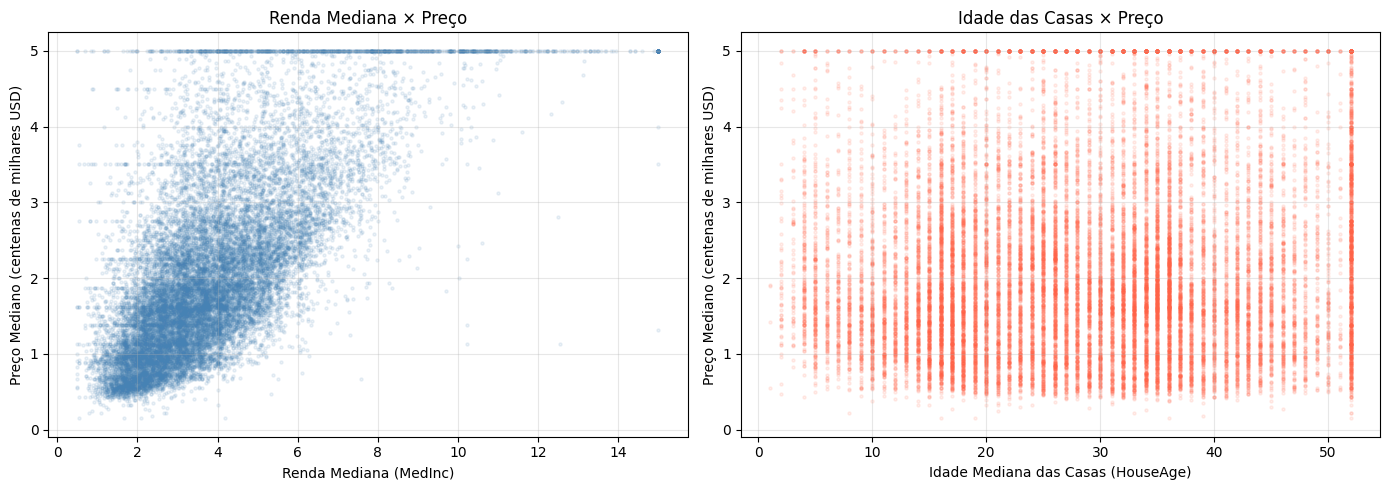

In [4]:
# Gráficos de dispersão de pelo menos duas variáveis contra o preço
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X['MedInc'], y, alpha=0.1, s=5, color='steelblue')
axes[0].set_xlabel('Renda Mediana (MedInc)')
axes[0].set_ylabel('Preço Mediano (centenas de milhares USD)')
axes[0].set_title('Renda Mediana × Preço')
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X['HouseAge'], y, alpha=0.1, s=5, color='tomato')
axes[1].set_xlabel('Idade Mediana das Casas (HouseAge)')
axes[1].set_ylabel('Preço Mediano (centenas de milhares USD)')
axes[1].set_title('Idade das Casas × Preço')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.3 Divisão em treino, validação e teste (70/15/15)

In [5]:
X_np = X.to_numpy().astype(np.float32)
y_np = y.to_numpy().astype(np.float32).reshape(-1, 1)

# Primeiro split: 70% treino, 30% temp
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    X_np, y_np, test_size=0.30, random_state=42)

# Segundo split: divide o temp em 50/50 → 15% val e 15% teste
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp_raw, y_temp_raw, test_size=0.50, random_state=42)

print(f'Treino:    {X_train_raw.shape[0]} amostras')
print(f'Validação: {X_val_raw.shape[0]} amostras')
print(f'Teste:     {X_test_raw.shape[0]} amostras')

Treino:    14448 amostras
Validação: 3096 amostras
Teste:     3096 amostras


### 1.4 Padronização com StandardScaler (ajustado **só no treino**)

O scaler é ajustado (`fit`) apenas com os dados de treino e depois aplicado (`transform`) a treino, validação e teste. Se usássemos todos os dados para ajustar, informação de validação e teste vazaria para o treino.

In [6]:
# Ajusta os scalers APENAS no treino
x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

# Converte para tensores float32
x_train = torch.from_numpy(x_scaler.transform(X_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()

x_val = torch.from_numpy(x_scaler.transform(X_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

x_test = torch.from_numpy(x_scaler.transform(X_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape,   ' y_val:  ', y_val.shape)
print('x_test: ', x_test.shape,  ' y_test: ', y_test.shape)

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])  y_val:   torch.Size([3096, 1])
x_test:  torch.Size([3096, 8])  y_test:  torch.Size([3096, 1])


## 2. Modelo

`nn.Linear(8, 1)` tem **8 entradas** (uma por variável) e **1 saída** (preço previsto).
O bias é incluído automaticamente (`bias=True` por padrão), então não precisamos da coluna de uns.

In [7]:
model = nn.Linear(8, 1)
print(model)
print('\nweight shape:', model.weight.shape)   # (1, 8): um peso por variável
print('bias shape:  ', model.bias.shape)       # (1,)

Linear(in_features=8, out_features=1, bias=True)

weight shape: torch.Size([1, 8])
bias shape:   torch.Size([1])


## 3. Treinamento

### 3.1 Função de custo e otimizador

Seguindo o padrão do notebook 2.6: `nn.MSELoss` e `optim.SGD`.

In [8]:
lr = 0.1
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

### 3.2 Funções de treino e validação

In [9]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### 3.3 Laço de treinamento

In [10]:
n_epochs = 200
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    val_loss   = validate_epoch(model, criterion, x_val, y_val)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}]  '
              f'Train Loss: {train_loss:.6f}  '
              f'Val Loss: {val_loss:.6f}')

Epoch[20/200]  Train Loss: 0.432361  Val Loss: 0.442328
Epoch[40/200]  Train Loss: 0.411845  Val Loss: 0.423407
Epoch[60/200]  Train Loss: 0.401785  Val Loss: 0.413999
Epoch[80/200]  Train Loss: 0.396518  Val Loss: 0.409107
Epoch[100/200]  Train Loss: 0.393754  Val Loss: 0.406560
Epoch[120/200]  Train Loss: 0.392300  Val Loss: 0.405233
Epoch[140/200]  Train Loss: 0.391533  Val Loss: 0.404541
Epoch[160/200]  Train Loss: 0.391127  Val Loss: 0.404178
Epoch[180/200]  Train Loss: 0.390910  Val Loss: 0.403986
Epoch[200/200]  Train Loss: 0.390795  Val Loss: 0.403884


### 3.4 Curvas de custo de treino e validação

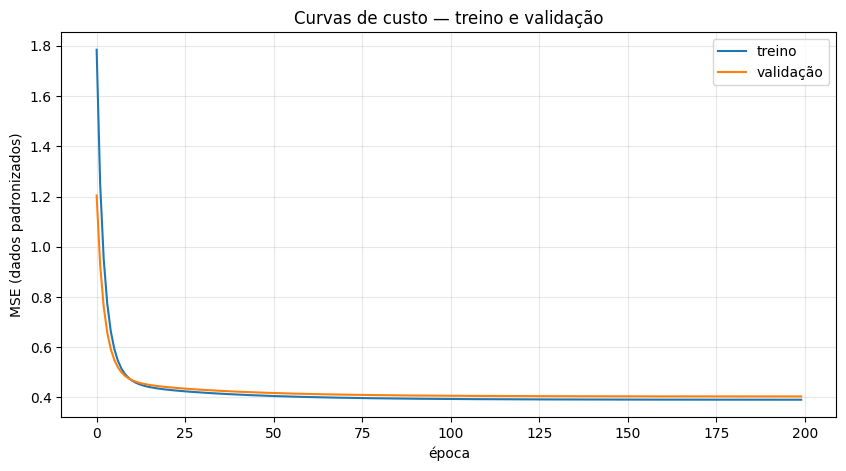

In [11]:
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='treino')
plt.plot(val_losses,   label='validação')
plt.xlabel('época')
plt.ylabel('MSE (dados padronizados)')
plt.title('Curvas de custo — treino e validação')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 4. Avaliação no conjunto de teste

### 4.1 RMSE em dólares vs baseline

O baseline prevê sempre o preço médio do treino — é o mínimo que qualquer modelo razoável deve superar.

In [12]:
model.eval()
with torch.no_grad():
    y_pred_test = model(x_test)

# Desnormaliza as previsões para a escala original (centenas de milhares)
y_pred_test_raw = y_scaler.inverse_transform(y_pred_test.numpy())

# Converte para dólares (* 100.000)
erros = (y_pred_test_raw - y_test_raw) * 100_000
rmse_teste = np.sqrt((erros ** 2).mean())

# Baseline: sempre prevê o preço médio do treino
media_treino = y_train_raw.mean()
erros_baseline = (media_treino - y_test_raw) * 100_000
rmse_baseline = np.sqrt((erros_baseline ** 2).mean())

print(f'RMSE do modelo no teste: $ {rmse_teste:,.0f}')
print(f'RMSE do baseline:        $ {rmse_baseline:,.0f}')
print(f'Melhoria sobre baseline: {(1 - rmse_teste/rmse_baseline)*100:.1f}%')

RMSE do modelo no teste: $ 72,012
RMSE do baseline:        $ 114,992
Melhoria sobre baseline: 37.4%


### 4.2 Os 8 pesos aprendidos

Como as entradas foram **padronizadas**, os pesos são comparáveis entre si:
- Peso **positivo alto** → variável aumenta o preço previsto
- Peso **negativo alto** (em valor absoluto) → variável diminui o preço previsto

Só faz sentido comparar os pesos entre si porque as entradas foram padronizadas: sem padronização, uma variável com escala maior teria peso artificialmente menor não porque importa menos, mas porque seus números já são grandes.

  Variável      Peso
    MedInc  0.733532
 AveBedrms  0.291062
  HouseAge  0.109458
Population  0.000634
  AveOccup -0.036394
  AveRooms -0.251023
 Longitude -0.720566
  Latitude -0.742754


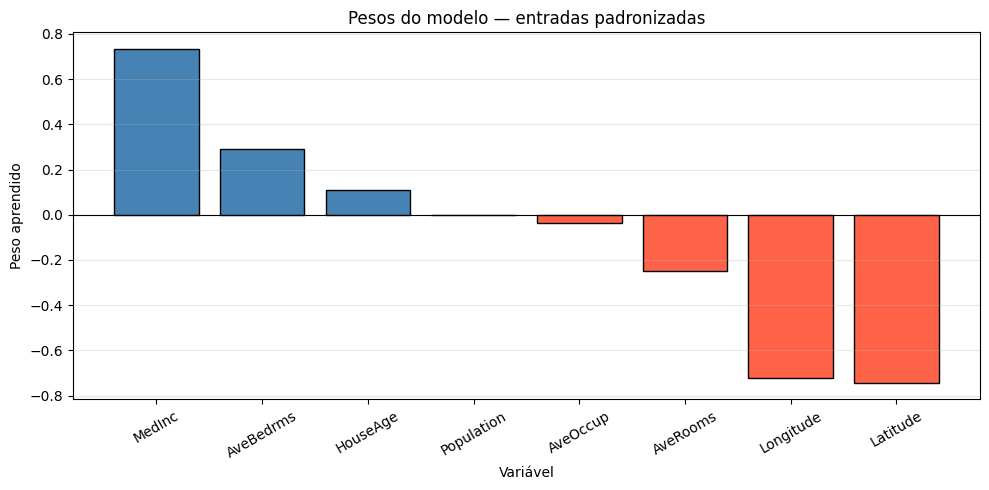

In [13]:
feature_names = X.columns.tolist()
pesos = model.weight.detach().numpy().flatten()

pesos_df = pd.DataFrame({
    'Variável': feature_names,
    'Peso': pesos
}).sort_values('Peso', ascending=False)

print(pesos_df.to_string(index=False))

# Gráfico de barras dos pesos
cores = ['steelblue' if p > 0 else 'tomato' for p in pesos_df['Peso']]
plt.figure(figsize=(10, 5))
plt.bar(pesos_df['Variável'], pesos_df['Peso'], color=cores, edgecolor='black')
plt.axhline(0, color='black', linewidth=0.8)
plt.xlabel('Variável')
plt.ylabel('Peso aprendido')
plt.title('Pesos do modelo — entradas padronizadas')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

*renda mediana do quarteirão com maior peso positivo e a latitude e longitude com maior peso negativo*

### 4.3 Exemplo de previsão para uma casa específica

In [14]:
# Características da casa que queremos prever
# [MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude]
casa_exemplo = np.array([[
    5.0,    # MedInc:     renda mediana do bairro ~$50k
    20.0,   # HouseAge:   casa com 20 anos
    6.0,    # AveRooms:   média de 6 cômodos
    1.0,    # AveBedrms:  média de 1 quarto
    1500.0, # Population: 1500 habitantes no quarteirão
    3.0,    # AveOccup:   3 moradores por domicílio
    34.0,   # Latitude:   sul da Califórnia (Los Angeles)
   -118.0   # Longitude:  Los Angeles
]], dtype=np.float32)

# Padroniza com o scaler ajustado no treino
casa_scaled = x_scaler.transform(casa_exemplo)
casa_tensor = torch.from_numpy(casa_scaled).float()

# Previsão
model.eval()
with torch.no_grad():
    preco_scaled = model(casa_tensor)

# Desnormaliza e converte para dólares
preco_raw = y_scaler.inverse_transform(preco_scaled.numpy())
preco_dolares = preco_raw[0, 0] * 100_000

print(f'Características da casa:')
print(f'  Localização:       Los Angeles (~34°N, -118°W)')
print(f'  Renda do bairro:   ~$50.000/ano')
print(f'  Idade da casa:     20 anos')
print(f'  Média de cômodos:  6')
print(f'\nPreço previsto pelo modelo: $ {preco_dolares:,.0f}')

Características da casa:
  Localização:       Los Angeles (~34°N, -118°W)
  Renda do bairro:   ~$50.000/ano
  Idade da casa:     20 anos
  Média de cômodos:  6

Preço previsto pelo modelo: $ 234,863


### 4.4 comparando com os 5 vizinhos próximos

Usando a distância euclidiana

In [15]:
# Encontra as 5 casas mais parecidas no conjunto de treino
from sklearn.metrics.pairwise import euclidean_distances

distancias = euclidean_distances(casa_scaled, x_scaler.transform(X_train_raw))
indices_proximos = distancias[0].argsort()[:5]

print('Casas mais parecidas no dataset e seus preços reais:')
for i, idx in enumerate(indices_proximos):
    preco_real = y_train_raw[idx, 0] * 100_000
    print(f'  Vizinho {i+1}: $ {preco_real:,.0f}')

print(f'\nPreço previsto: $ {preco_dolares:,.0f}')

Casas mais parecidas no dataset e seus preços reais:
  Vizinho 1: $ 166,300
  Vizinho 2: $ 158,800
  Vizinho 3: $ 258,300
  Vizinho 4: $ 263,800
  Vizinho 5: $ 249,200

Preço previsto: $ 234,863


*a previsão é consistente com casas reais de características similares no dataset, o que dá confiança de que o modelo aprendeu um padrão real, não apenas memorizou ruído.*

## 5. Conclusão

### O modelo é bom o suficiente? O que tentaria para melhorar?

**Desempenho obtido:**
- RMSE do modelo no teste: $ 72,012

- RMSE do baseline:        $ 114,992

- Melhoria sobre baseline: 37.4%

**O modelo é bom o suficiente?**

Um modelo de regressão linear com 8 variáveis já captura bem a tendência geral dos dados. Porém, o preço de casas tem relações **não lineares** (localização influencia o preço de forma complexa, interações entre variáveis, etc.) que uma reta não consegue capturar completamente.

**O que tentaria para melhorar:**
1. **Adicionar não linearidades** — usar uma rede neural com camadas ocultas e funções de ativação (ReLU)
2. **Mais épocas ou lr ajustado** — verificar se o modelo ainda não convergiu totalmente
3. **Engenharia de features** — combinar variáveis existentes (ex: quartos/cômodos, renda × localização)
4. **Remover outliers** — alguns quarteirões têm valores extremos que podem prejudicar o treino